In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
print(df.shape[0], df.shape[1])
df.info()

891 12
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": (df.isnull().mean() * 100).round(2)
})
print(missing[missing["Missing"] > 0])

          Missing  Percent
Age           177    19.87
Cabin         687    77.10
Embarked        2     0.22


In [4]:
# Drop non-predictive identifier columns
df_clean = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore").copy()
numeric_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Total missing values after imputation:", df_clean.isnull().sum().sum())

Total missing values after imputation: 0


In [5]:
for col in categorical_cols:
    print(col, df_clean[col].unique())

df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)
print("Encoded shape:", df_encoded.shape)
print(df_encoded.head())

demo_col = "Sex"
codes = LabelEncoder().fit_transform(df_clean[demo_col].astype(str))
print(pd.DataFrame({demo_col: df_clean[demo_col], "Encoded": codes}).head())

Sex <ArrowStringArray>
['male', 'female']
Length: 2, dtype: str
Embarked <ArrowStringArray>
['S', 'C', 'Q']
Length: 3, dtype: str
Encoded shape: (891, 9)
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500      True       False   
1         1       1  38.0      1      0  71.2833     False       False   
2         1       3  26.0      0      0   7.9250     False       False   
3         1       1  35.0      1      0  53.1000     False       False   
4         0       3  35.0      0      0   8.0500      True       False   

   Embarked_S  
0        True  
1       False  
2        True  
3        True  
4        True  
      Sex  Encoded
0    male        1
1  female        0
2  female        0
3  female        0
4    male        1


In [6]:
std_df = pd.DataFrame(StandardScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)
mm_df = pd.DataFrame(MinMaxScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)

print("Standard Scaler summary:\n", std_df.agg(["mean", "std"]).round(2))
print("MinMax Scaler summary:\n", mm_df.agg(["min", "max"]).round(2))

Standard Scaler summary:
       Survived  Pclass  Age  SibSp  Parch  Fare
mean       0.0    -0.0  0.0    0.0    0.0   0.0
std        1.0     1.0  1.0    1.0    1.0   1.0
MinMax Scaler summary:
      Survived  Pclass  Age  SibSp  Parch  Fare
min       0.0     0.0  0.0    0.0    0.0   0.0
max       1.0     1.0  1.0    1.0    1.0   1.0


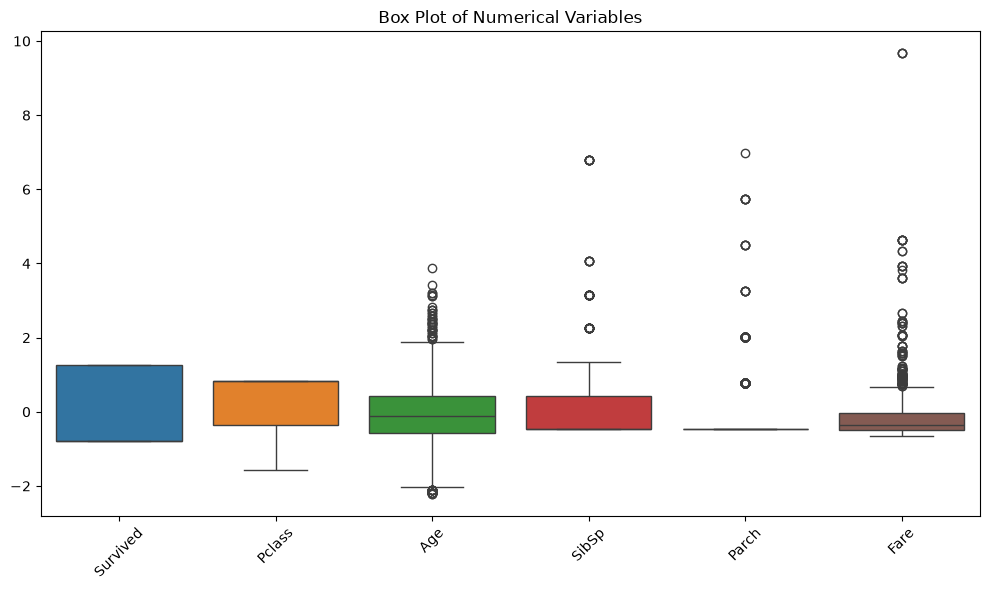

     Column       Q1    Q3      IQR   Lower    Upper  Outliers
0  Survived   0.0000   1.0   1.0000  -1.500   2.5000         0
1    Pclass   2.0000   3.0   1.0000   0.500   4.5000         0
2       Age  22.0000  35.0  13.0000   2.500  54.5000        66
3     SibSp   0.0000   1.0   1.0000  -1.500   2.5000        46
4     Parch   0.0000   0.0   0.0000   0.000   0.0000       213
5      Fare   7.9104  31.0  23.0896 -26.724  65.6344       116


In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=std_df)
plt.title("Box Plot of Numerical Variables")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rows = []
for col in numeric_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    rows.append([col, q1, q3, iqr, lo, hi, n_out])

iqr_table = pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"])
print(iqr_table)

In [8]:
outlier_col = "Fare"
lo, hi = iqr_table.set_index("Column").loc[outlier_col, ["Lower", "Upper"]]
df_final = df_clean[df_clean[outlier_col].between(lo, hi)].copy()
print(f"Original rows: {len(df_clean)} | After outlier removal on {outlier_col}: {len(df_final)}")

Original rows: 891 | After outlier removal on Fare: 775


In [9]:
df_final.to_csv("preprocessed_dataset.csv", index=False)
print("Saved preprocessed dataset to preprocessed_dataset.csv")

Saved preprocessed dataset to preprocessed_dataset.csv
